# Exploración de datos — Evaluación de historias cinematográficas
## Proyecto · Entrega 1


In [ ]:
from pathlib import Path
import sys, ast, re, json, hashlib, platform
from datetime import datetime, timezone
from urllib.request import urlretrieve
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.feature_extraction.text import CountVectorizer

BASE=Path.cwd()
DATA=BASE/'data'
FIG=BASE/'figuras'
DATA.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':160,'font.size':10,
                     'axes.spines.top':False,'axes.spines.right':False})
COLOR='#4945A5'
def guardar_figura(nombre):
    plt.tight_layout()
    plt.savefig(FIG/nombre,bbox_inches='tight')
    plt.show()

print('Python:',platform.python_version(),'| pandas:',pd.__version__,
      '| numpy:',np.__version__,'| matplotlib:',matplotlib.__version__)

Python: 3.13.16 | pandas: 2.2.3 | numpy: 2.1.3 | matplotlib: 3.10.0


## 1. Disponibilidad y trazabilidad


In [ ]:
urls={name:f'https://raw.githubusercontent.com/albahnsen/MIAD_ML_and_NLP/main/datasets/{name}.zip'
      for name in ['dataTraining','dataTesting']}
manifest=[]
for name,url in urls.items():
    p=DATA/f'{name}.zip'
    if not p.exists():
        urlretrieve(url,p)
    manifest.append({'archivo':p.name,'bytes':p.stat().st_size,
                     'sha256':hashlib.sha256(p.read_bytes()).hexdigest(),'fuente':url})
pd.DataFrame(manifest).to_csv(BASE/'manifest_datos.csv',index=False)
display(pd.DataFrame(manifest))
train=pd.read_csv(DATA/'dataTraining.zip',index_col=0)
test=pd.read_csv(DATA/'dataTesting.zip',index_col=0)
assert set(train.columns)=={'year','title','plot','genres','rating'}
assert set(test.columns)=={'year','title','plot'}
display(pd.DataFrame({'conjunto':['Entrenamiento etiquetado','Prueba sin etiquetas'],
                      'registros':[len(train),len(test)],'columnas':[train.shape[1],test.shape[1]]}))
display(train.head())

,archivo,bytes,sha256,fuente
0,dataTraining.zip,2353381,d217985a0aedcf17c6a4519582352bba8beb58d9c41864...,https://raw.githubusercontent.com/albahnsen/MI...
1,dataTesting.zip,972989,54d3040773a092eed06f01cf55da61551cd9ab466ac6e7...,https://raw.githubusercontent.com/albahnsen/MI...


,conjunto,registros,columnas
0,Entrenamiento etiquetado,7895,5
1,Prueba sin etiquetas,3383,3


,year,title,plot,genres,rating
3107,2003,Most,most is the story of a single father who takes...,"['Short', 'Drama']",8.0
900,2008,How to Be a Serial Killer,a serial killer decides to teach the secrets o...,"['Comedy', 'Crime', 'Horror']",5.6
6724,1941,A Woman's Face,"in sweden , a female blackmailer with a disfi...","['Drama', 'Film-Noir', 'Thriller']",7.2
4704,1954,Executive Suite,"in a friday afternoon in new york , the presi...",['Drama'],7.4
2582,1990,Narrow Margin,"in los angeles , the editor of a publishing h...","['Action', 'Crime', 'Thriller']",6.6


## 2. Diccionario de datos y calidad


In [ ]:
diccionario=pd.DataFrame([
 ['year','Entero','Año de la película','Metadato; no representa un año futuro conocido'],
 ['title','Texto','Título de la película','Metadato opcional'],
 ['plot','Texto','Trama o sinopsis','Predictor principal'],
 ['genres','Lista almacenada como texto','Géneros de la película','Objetivo de clasificación'],
 ['rating','Decimal','Valoración histórica','Objetivo de regresión']
],columns=['variable','tipo','descripción','uso'])
display(diccionario)
calidad=[]
for nombre,df in [('entrenamiento',train),('prueba',test)]:
    for col in df:
        vacios=int(df[col].fillna('').astype(str).str.strip().eq('').sum()) if df[col].dtype=='object' else 0
        calidad.append([nombre,col,str(df[col].dtype),int(df[col].isna().sum()),vacios])
calidad=pd.DataFrame(calidad,columns=['conjunto','columna','tipo','nulos','vacíos_texto'])
display(calidad)
duplicados=pd.DataFrame([
 [n,int(d.duplicated().sum()),int(d.duplicated(['title','year']).sum()),int(d.duplicated(['plot']).sum())]
 for n,d in [('entrenamiento',train),('prueba',test)]
],columns=['conjunto','duplicados_completos','repeticiones_título_año','repeticiones_trama'])
display(duplicados)
display(train.loc[train.duplicated(keep=False),['title','year','rating']])
print('Coincidencias título-año entre conjuntos:',len(set(zip(train.title,train.year))&set(zip(test.title,test.year))))
print('Coincidencias exactas de trama entre conjuntos:',len(set(train['plot'])&set(test['plot'])))
print('Ratings fuera de [0,10]:',int((~train.rating.between(0,10)).sum()))

,variable,tipo,descripción,uso
0,year,Entero,Año de la película,Metadato; no representa un año futuro conocido
1,title,Texto,Título de la película,Metadato opcional
2,plot,Texto,Trama o sinopsis,Predictor principal
3,genres,Lista almacenada como texto,Géneros de la película,Objetivo de clasificación
4,rating,Decimal,Valoración histórica,Objetivo de regresión


,conjunto,columna,tipo,nulos,vacíos_texto
0,entrenamiento,year,int64,0,0
1,entrenamiento,title,object,0,0
2,entrenamiento,plot,object,0,0
3,entrenamiento,genres,object,0,0
4,entrenamiento,rating,float64,0,0
5,prueba,year,int64,0,0
6,prueba,title,object,0,0
7,prueba,plot,object,0,0


,conjunto,duplicados_completos,repeticiones_título_año,repeticiones_trama
0,entrenamiento,1,3,1
1,prueba,0,0,0


,title,year,rating
1297,Gekijô-ban poketto monsutâ: Maboroshi no pokem...,1999,5.9
2284,Gekijô-ban poketto monsutâ: Maboroshi no pokem...,1999,5.9


Coincidencias título-año entre conjuntos: 0
Coincidencias exactas de trama entre conjuntos: 0
Ratings fuera de [0,10]: 0


In [ ]:
import pandas as pd

def resumir_calidad(df):
    return {
        "Registros": len(df),
        "Valores nulos": int(df.isna().sum().sum()),
        "Títulos o tramas vacíos": int(
            df[["title", "plot"]]
            .fillna("")
            .apply(lambda columna: columna.str.strip().eq(""))
            .any(axis=1)
            .sum()
        ),
        "Duplicados completos adicionales": int(df.duplicated().sum()),
        "Periodo de las películas": (
            f"{df['year'].min()}–{df['year'].max()}"
        ),
        "Mediana de extensión de la trama": (
            df["plot"].str.split().str.len().median()
        )
    }

tabla_calidad = pd.DataFrame({
    "Entrenamiento": resumir_calidad(train),
    "Prueba": resumir_calidad(test)
})

display(tabla_calidad)

,Entrenamiento,Prueba
Registros,7895,3383
Valores nulos,0,0
Títulos o tramas vacíos,0,0
Duplicados completos adicionales,1,0
Periodo de las películas,1894–2015,1893–2015
Mediana de extensión de la trama,127.0,127.0


## 3. Variable central de negocio: rating
La exploración del rating permite identificar qué valoraciones son frecuentes y qué tan representadas están las películas con calificaciones extremas.

,rating
count,7895.000
mean,6.403
std,1.078
min,1.200
25%,5.800
50%,6.500
75%,7.200
max,9.300


,películas,porcentaje
rating,,
"(-0.001, 2.0]",11,0.14
"(2.0, 4.0]",228,2.89
"(4.0, 6.0]",2345,29.70
"(6.0, 8.0]",5085,64.41
"(8.0, 10.0]",226,2.86


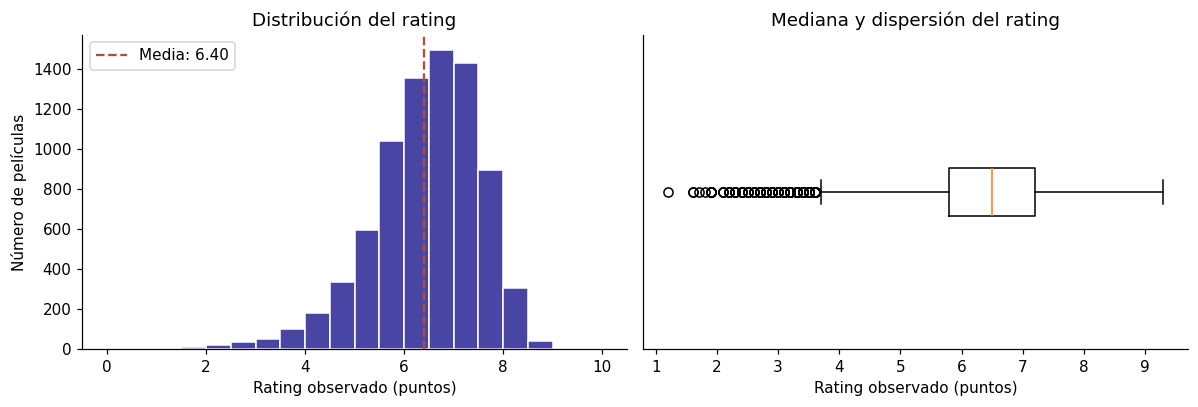

Porcentaje con rating >6 y <=8: 64.41


In [ ]:
resumen_rating=train.rating.describe().to_frame('rating')
display(resumen_rating.round(3))
intervalos=pd.cut(train.rating,[0,2,4,6,8,10],include_lowest=True)
tabla_rating=intervalos.value_counts(sort=False).rename('películas').to_frame()
tabla_rating['porcentaje']=100*tabla_rating['películas']/len(train)
display(tabla_rating.round(2))
fig,ax=plt.subplots(1,2,figsize=(11,3.8))
ax[0].hist(train.rating,bins=np.arange(0,10.5,.5),color=COLOR,edgecolor='white')
ax[0].axvline(train.rating.mean(),color='#B84B33',linestyle='--',label=f'Media: {train.rating.mean():.2f}')
ax[0].set(xlabel='Rating observado (puntos)',ylabel='Número de películas',title='Distribución del rating')
ax[0].legend()
ax[1].boxplot(train.rating,vert=False)
ax[1].set(xlabel='Rating observado (puntos)',yticks=[],title='Mediana y dispersión del rating')
guardar_figura('01_rating.png')
print('Porcentaje con rating >6 y <=8:',round(100*train.rating.between(6,8,inclusive='right').mean(),2))

## 4. Géneros: desbalance, coexistencia y relación con rating
Una película puede pertenecer a varios géneros.

,películas,porcentaje
Drama,3965,50.22
Comedy,3046,38.58
Thriller,2024,25.64
Romance,1892,23.96
Crime,1447,18.33
Action,1303,16.50
Adventure,1024,12.97
Horror,954,12.08
Mystery,759,9.61
Sci-Fi,723,9.16


,películas
genres,
1,1172
2,2405
3,2419
4,1300
5,489
6,85
7,20
8,3
9,2


Promedio de géneros: 2.733


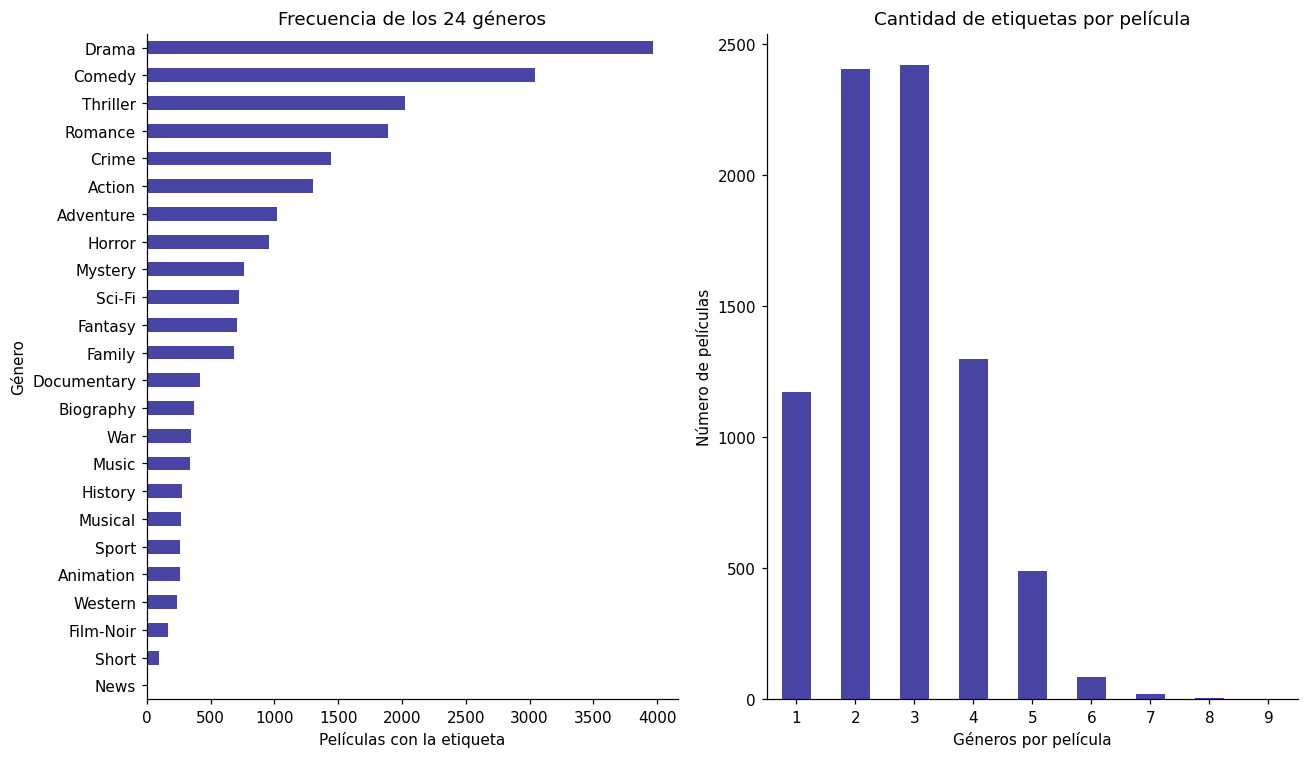

,count,mean,median,std
genero,,,,
Drama,3965,6.654,6.70,0.876
Comedy,3046,6.201,6.30,1.051
Thriller,2024,6.204,6.20,1.011
Romance,1892,6.525,6.60,0.909
Crime,1447,6.465,6.50,0.953
Action,1303,6.026,6.10,1.122
Adventure,1024,6.309,6.50,1.157
Horror,954,5.646,5.70,1.119
Mystery,759,6.427,6.50,0.943


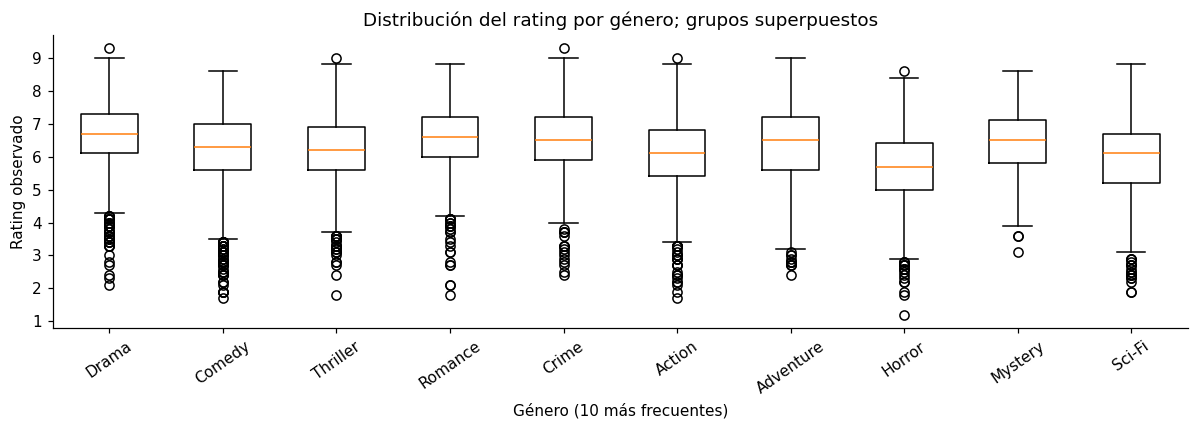

In [ ]:
generos=train.genres.apply(ast.literal_eval)
assert generos.apply(lambda v:isinstance(v,list) and all(isinstance(g,str) for g in v)).all()
freq=pd.Series(Counter(g for lista in generos for g in set(lista))).sort_values(ascending=False)
tabla_generos=pd.DataFrame({'películas':freq,'porcentaje':100*freq/len(train)})
display(tabla_generos.round(2))
num_generos=generos.str.len()
display(num_generos.value_counts().sort_index().rename('películas').to_frame())
print('Promedio de géneros:',round(num_generos.mean(),3))
fig,ax=plt.subplots(1,2,figsize=(12,7))
freq.sort_values().plot.barh(ax=ax[0],color=COLOR)
ax[0].set(xlabel='Películas con la etiqueta',ylabel='Género',title='Frecuencia de los 24 géneros')
num_generos.value_counts().sort_index().plot.bar(ax=ax[1],color=COLOR,rot=0)
ax[1].set(xlabel='Géneros por película',ylabel='Número de películas',title='Cantidad de etiquetas por película')
guardar_figura('02_generos.png')
long=train[['rating']].assign(genero=generos).explode('genero')
por_genero=long.groupby('genero').rating.agg(['count','mean','median','std']).sort_values('count',ascending=False)
display(por_genero.round(3))
top=freq.head(10).index.tolist()
fig,ax=plt.subplots(figsize=(11,4))
ax.boxplot([long.loc[long.genero.eq(g),'rating'] for g in top],tick_labels=top,vert=True)
ax.tick_params(axis='x',rotation=35)
ax.set(xlabel='Género (10 más frecuentes)',ylabel='Rating observado',title='Distribución del rating por género; grupos superpuestos')
guardar_figura('03_rating_por_genero.png')

## 5. Contenido y longitud de las tramas


,entrenamiento,prueba
count,7895.00,3383.00
mean,144.77,145.11
std,95.82,94.03
min,1.00,1.00
25%,80.00,81.00
50%,127.00,127.00
75%,183.00,181.00
max,1863.00,740.00


,tokens alfabéticos
count,7895.00
mean,126.64
std,84.42
min,1.00
25%,70.00
50%,110.00
75%,161.00
max,1723.00


Tramas con menos de 10 elementos: 17


,title,plot,palabras,rating
2145,Blue Collar,"three workers , zeke (",5,7.6
7444,I Am Divine,how,1,7.7
4832,Cobain: Montage of Heck,an authorized documentary on the late musician,7,7.6
4110,3 A.M.,the feature film directing debut of,6,5.9
9425,The Endurance: Shackleton's Legendary Antarcti...,a retelling of sir,4,7.9
1441,U2 3D,a N - d presentation of,6,8.4
10298,Wild Man Blues,academy award - winner,4,7.0
9143,Full Tilt Boogie,a documentary about the production of,6,6.5
2766,George Harrison: Living in the Material World,filmmaker,1,8.2
7709,One Chance,the true story of,4,6.8


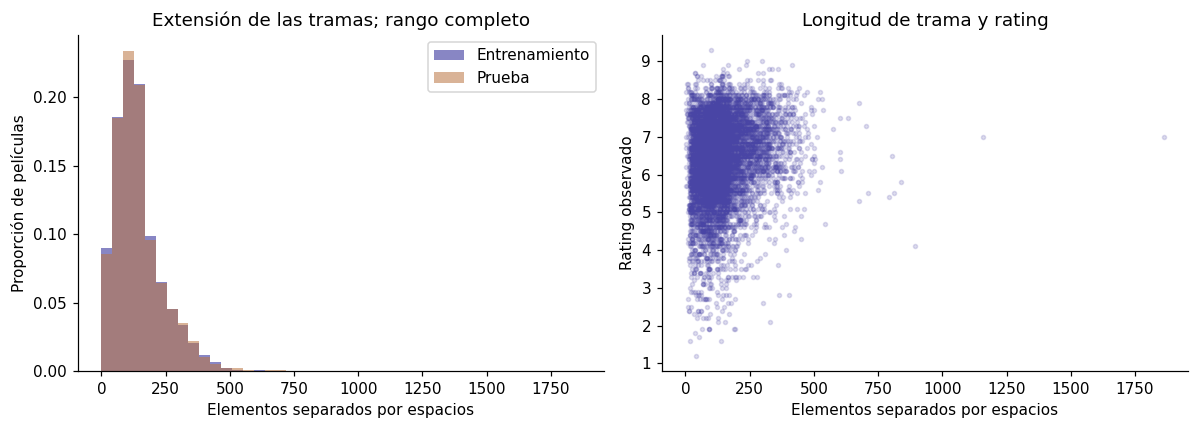

,year,rating,palabras
year,1.000,-0.292,-0.057
rating,-0.292,1.000,0.164
palabras,-0.057,0.164,1.000


In [ ]:
train_eda=train.assign(palabras=train['plot'].str.split().str.len(),
                       tokens_alfabeticos=train['plot'].str.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?").str.len())
test_eda=test.assign(palabras=test['plot'].str.split().str.len())
display(pd.DataFrame({'entrenamiento':train_eda.palabras.describe(),
                      'prueba':test_eda.palabras.describe()}).round(2))
display(train_eda.tokens_alfabeticos.describe().round(2).to_frame('tokens alfabéticos'))
print('Tramas con menos de 10 elementos:',int(train_eda.palabras.lt(10).sum()))
display(train_eda.loc[train_eda.palabras.lt(10),['title','plot','palabras','rating']])
fig,ax=plt.subplots(1,2,figsize=(11,4))
bins=np.linspace(0,max(train_eda.palabras.max(),test_eda.palabras.max()),45)
ax[0].hist(train_eda.palabras,bins=bins,weights=np.ones(len(train))/len(train),
           alpha=.65,label='Entrenamiento',color=COLOR)
ax[0].hist(test_eda.palabras,bins=bins,weights=np.ones(len(test))/len(test),
           alpha=.55,label='Prueba',color='#BA7542')
ax[0].set(xlabel='Elementos separados por espacios',ylabel='Proporción de películas',title='Extensión de las tramas; rango completo')
ax[0].legend()
ax[1].scatter(train_eda.palabras,train_eda.rating,s=7,alpha=.18,color=COLOR)
ax[1].set(xlabel='Elementos separados por espacios',ylabel='Rating observado',title='Longitud de trama y rating')
guardar_figura('04_texto.png')
correlacion=train_eda[['year','rating','palabras']].corr()
display(correlacion.round(3))

,apariciones
life,2721
new,2255
man,1927
family,1599
love,1530
father,1454
time,1433
young,1356
old,1249
finds,1243


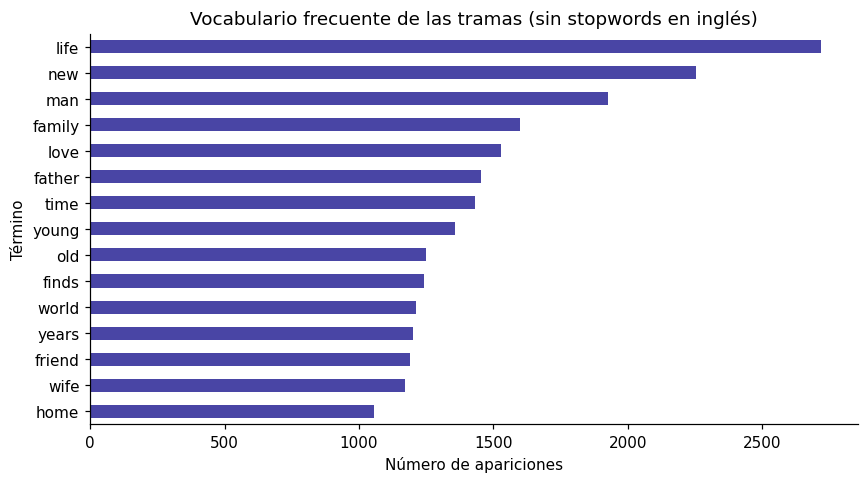

In [ ]:
cv=CountVectorizer(stop_words='english',min_df=5,max_features=20000)
conteos=cv.fit_transform(train['plot'])
frecuencia_terminos=pd.Series(np.asarray(conteos.sum(axis=0)).ravel(),index=cv.get_feature_names_out()).sort_values(ascending=False)
display(frecuencia_terminos.head(20).rename('apariciones').to_frame())
fig,ax=plt.subplots(figsize=(8,4.5))
frecuencia_terminos.head(15).sort_values().plot.barh(ax=ax,color=COLOR)
ax.set(xlabel='Número de apariciones',ylabel='Término',title='Vocabulario frecuente de las tramas (sin stopwords en inglés)')
guardar_figura('05_vocabulario.png')

## 6. Cobertura temporal y comparabilidad de los conjuntos
Se comparan proporciones por década, no conteos absolutos, porque los tamaños de los conjuntos son diferentes. El periodo más reciente termina en 2015: aplicar el producto a nuevas historias requiere comprobar generalización temporal.

,entrenamiento_pct,prueba_pct
decada,,
1890,0.04,0.03
1900,0.01,0.00
1910,0.25,0.33
1920,0.99,1.06
1930,2.84,3.16
1940,4.75,4.32
1950,5.21,4.94
1960,4.74,5.41
1970,5.95,6.95


Años entrenamiento: 1894 2015
Años prueba: 1893 2015


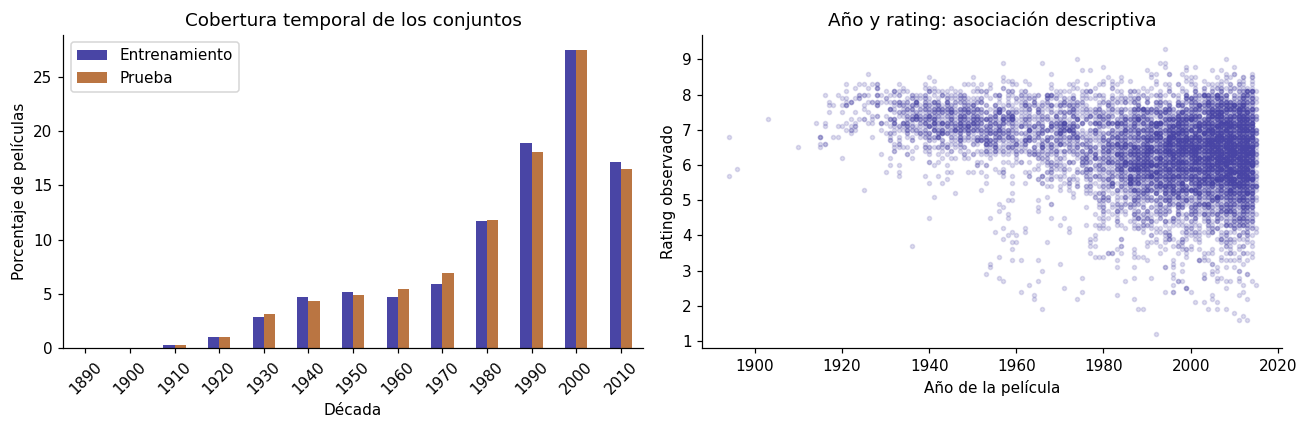

,count,mean,median
decada,,,
1890,3,6.13,5.90
1900,1,7.30,7.30
1910,20,7.10,6.95
1920,78,7.60,7.70
1930,224,7.29,7.30
1940,375,7.20,7.20
1950,411,6.94,7.10
1960,374,6.78,6.90
1970,470,6.63,6.80


In [ ]:
train_eda['decada']=train_eda.year//10*10
test_eda['decada']=test_eda.year//10*10
decadas=pd.DataFrame({'entrenamiento_pct':train_eda.decada.value_counts(normalize=True)*100,
                       'prueba_pct':test_eda.decada.value_counts(normalize=True)*100}).fillna(0).sort_index()
display(decadas.round(2))
print('Años entrenamiento:',train.year.min(),train.year.max())
print('Años prueba:',test.year.min(),test.year.max())
fig,ax=plt.subplots(1,2,figsize=(12,4))
decadas.plot.bar(ax=ax[0],color=[COLOR,'#BA7542'],rot=45)
ax[0].set(xlabel='Década',ylabel='Porcentaje de películas',title='Cobertura temporal de los conjuntos')
ax[0].legend(['Entrenamiento','Prueba'])
por_decada=train_eda.groupby('decada').rating.agg(['count','mean','median'])
ax[1].scatter(train.year,train.rating,s=7,alpha=.18,color=COLOR)
ax[1].set(xlabel='Año de la película',ylabel='Rating observado',title='Año y rating: asociación descriptiva')
guardar_figura('06_temporal.png')
display(por_decada.round(2))

**Interpretación:** el entrenamiento cubre **1894–2015** y prueba **1893–2015**; ambos se concentran en décadas recientes dentro de ese periodo. La correlación entre año y rating es **−0,29**. Esto puede reflejar composición de la muestra y sesgo de selección, no una superioridad de las películas antiguas. La similitud de longitud y década no demuestra igualdad en contenido ni en valoración, que no es observable en prueba.